# PRCP-1018: Bike Rental Demand Analysis and Prediction

**Project objective**

1. Prepare a complete data analysis report on the bike-sharing data.
2. Predict the daily bike rental count using environmental and seasonal settings.
3. Compare multiple machine-learning models and recommend a model for production.
4. Document data challenges and the techniques used to address them.

**Dataset:** UCI Bike Sharing Dataset (`day.csv` and `hour.csv`).  
**Target variable:** `cnt` — total daily rental bikes.

> Run the notebook from top to bottom. The first code cell downloads and extracts the dataset using the project-provided download link. Evaluation metrics and plots are generated from the actual data when the notebook is run; no results are hard-coded.


## 1. Import libraries and set up the dataset

In [1]:
import os
import zipfile
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor

RANDOM_STATE = 42
DATA_DIR = Path("bike_rental_data")
DATA_DIR.mkdir(exist_ok=True)

DATA_URL = "https://d3ilbtxij3aepc.cloudfront.net/projects/CDS-Capstone-Projects/PRCP-1018-BikeRental.zip"
ZIP_PATH = DATA_DIR / "PRCP-1018-BikeRental.zip"

if not ZIP_PATH.exists():
    print("Downloading project dataset...")
    urllib.request.urlretrieve(DATA_URL, ZIP_PATH)

with zipfile.ZipFile(ZIP_PATH, "r") as zf:
    zf.extractall(DATA_DIR)

csv_files = list(DATA_DIR.rglob("day.csv"))
if not csv_files:
    raise FileNotFoundError("day.csv was not found after extraction. Check the dataset download and ZIP contents.")

day_path = csv_files[0]
day = pd.read_csv(day_path)
print("Loaded:", day_path)
print("Dataset shape:", day.shape)
day.head()


Loaded: bike_rental_data\Data\day.csv
Dataset shape: (731, 16)


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


## 2. Understand the data

The project brief describes these important fields:

- `dteday`: date of the record
- `season`: season (1 = winter, 2 = spring, 3 = summer, 4 = fall)
- `yr`: year (0 = 2011, 1 = 2012)
- `mnth`: month
- `holiday`: whether the day is a holiday
- `weekday`: day of the week
- `workingday`: whether the day is neither weekend nor holiday
- `weathersit`: weather situation (1 = clear, 2 = mist/cloudy, 3 = light rain/snow, 4 = heavy rain/snow)
- `temp`, `atemp`, `hum`, `windspeed`: normalized weather measurements
- `casual`, `registered`: casual and registered rental counts
- `cnt`: total rental count (prediction target)

The daily dataset does not contain the `hr` (hour) column.


In [2]:
print("Rows and columns:", day.shape)
print("\\nColumn information:")
day.info()
print("\\nFirst five rows:")
display(day.head())
print("\\nSummary statistics:")
display(day.describe(include="all").T)
print("\\nMissing values:")
display(day.isna().sum().sort_values(ascending=False).to_frame("missing_count"))
print("\\nDuplicate rows:", day.duplicated().sum())


Rows and columns: (731, 16)
\nColumn information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB
\nFirst five rows:


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


\nSummary statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
instant,731.0,NaN,NaN,NaN,366.0,211.165812,1.0,183.5,366.0,548.5,731.0
dteday,731,731,2011-01-01,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
season,731.0,NaN,NaN,NaN,2.49658,1.110807,1.0,2.0,3.0,3.0,4.0
yr,731.0,NaN,NaN,NaN,0.500684,0.500342,0.0,0.0,1.0,1.0,1.0
mnth,731.0,NaN,NaN,NaN,6.519836,3.451913,1.0,4.0,7.0,10.0,12.0
holiday,731.0,NaN,NaN,NaN,0.028728,0.167155,0.0,0.0,0.0,0.0,1.0
weekday,731.0,NaN,NaN,NaN,2.997264,2.004787,0.0,1.0,3.0,5.0,6.0
workingday,731.0,NaN,NaN,NaN,0.683995,0.465233,0.0,0.0,1.0,1.0,1.0
weathersit,731.0,NaN,NaN,NaN,1.395349,0.544894,1.0,1.0,1.0,2.0,3.0
temp,731.0,NaN,NaN,NaN,0.495385,0.183051,0.05913,0.337083,0.498333,0.655417,0.861667


\nMissing values:


,missing_count
instant,0
dteday,0
season,0
yr,0
mnth,0
holiday,0
weekday,0
workingday,0
weathersit,0
temp,0


\nDuplicate rows: 0


## 3. Data cleaning and preparation

In [3]:
data = day.copy()

# Convert date column to datetime and sort chronologically.
data["dteday"] = pd.to_datetime(data["dteday"], errors="coerce")
data = data.dropna(subset=["dteday", "cnt"]).sort_values("dteday").reset_index(drop=True)

# Remove exact duplicate rows, if any.
data = data.drop_duplicates().reset_index(drop=True)

# Add calendar features from the date.
data["day_of_month"] = data["dteday"].dt.day
data["day_of_year"] = data["dteday"].dt.dayofyear
data["is_month_start"] = data["dteday"].dt.is_month_start.astype(int)
data["is_month_end"] = data["dteday"].dt.is_month_end.astype(int)

print("Shape after basic cleaning:", data.shape)
print("Missing values after basic cleaning:")
display(data.isna().sum().to_frame("missing_count"))


Shape after basic cleaning: (731, 20)
Missing values after basic cleaning:


,missing_count
instant,0
dteday,0
season,0
yr,0
mnth,0
holiday,0
weekday,0
workingday,0
weathersit,0
temp,0


### Target and leakage prevention

The target is `cnt`. The columns `casual` and `registered` are excluded from the predictors because their sum directly makes up `cnt`; using them would leak the answer into the model. `instant` is only a record index, and `dteday` is represented through calendar features rather than passed as raw text.

The `yr` feature is retained because it is available as a calendar indicator in the supplied dataset. For a real future deployment, the training and validation period should be chosen to reflect the intended prediction horizon.


In [4]:
TARGET = "cnt"
drop_columns = ["cnt", "casual", "registered", "instant", "dteday"]
X = data.drop(columns=[c for c in drop_columns if c in data.columns])
y = data[TARGET].astype(float)

# Treat coded categories as categorical rather than continuous numeric measurements.
categorical_candidates = ["season", "yr", "mnth", "holiday", "weekday", "workingday", "weathersit"]
categorical_features = [c for c in categorical_candidates if c in X.columns]
numeric_features = [c for c in X.columns if c not in categorical_features]

for col in categorical_features:
    X[col] = X[col].astype("Int64").astype(str)

print("Predictor columns:", X.columns.tolist())
print("Categorical features:", categorical_features)
print("Numeric features:", numeric_features)
print("Target range:", y.min(), "to", y.max())


Predictor columns: ['season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'day_of_month', 'day_of_year', 'is_month_start', 'is_month_end']
Categorical features: ['season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit']
Numeric features: ['temp', 'atemp', 'hum', 'windspeed', 'day_of_month', 'day_of_year', 'is_month_start', 'is_month_end']
Target range: 22.0 to 8714.0


## 4. Exploratory data analysis (EDA)

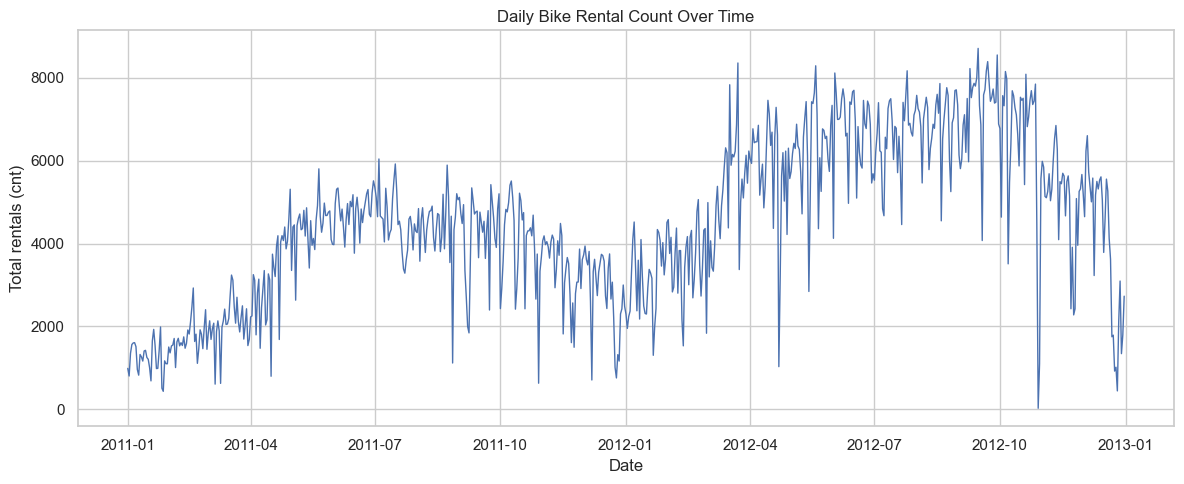

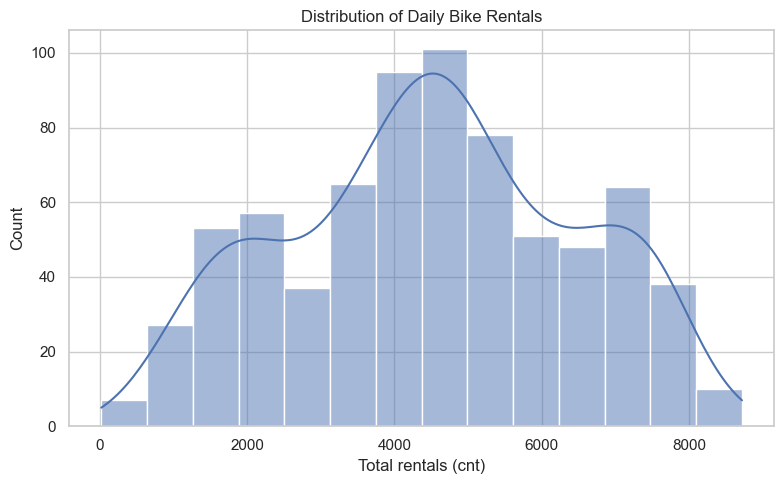

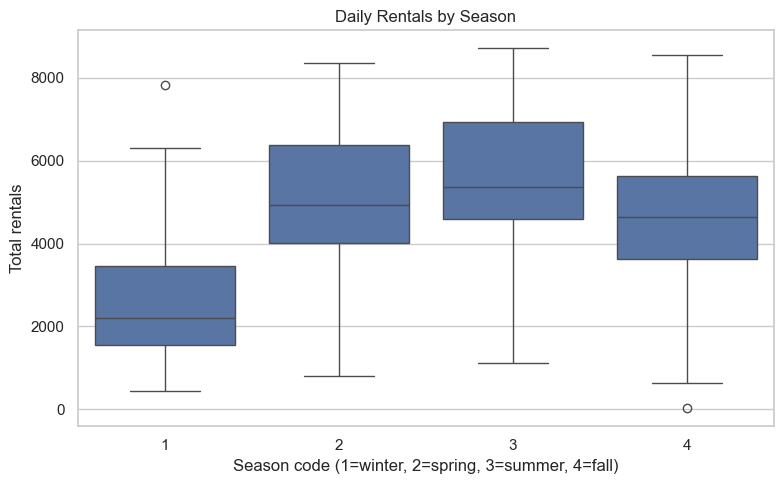

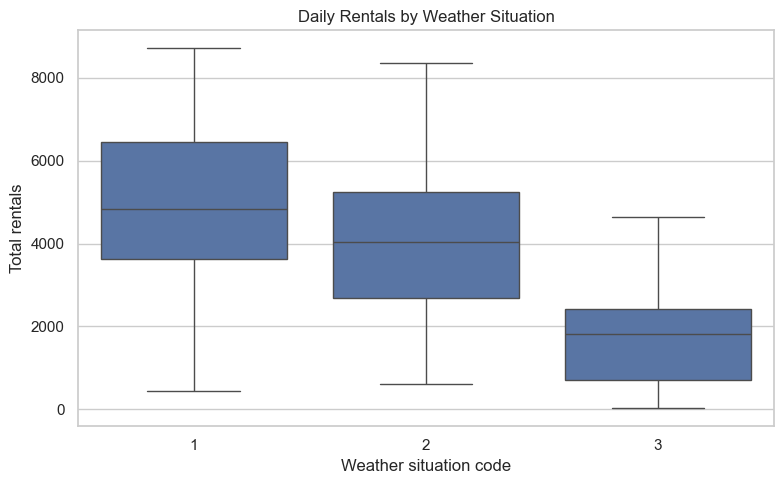

In [5]:
sns.set_theme(style="whitegrid")

plt.figure(figsize=(12, 5))
plt.plot(data["dteday"], data["cnt"], linewidth=1)
plt.title("Daily Bike Rental Count Over Time")
plt.xlabel("Date")
plt.ylabel("Total rentals (cnt)")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
sns.histplot(data["cnt"], kde=True)
plt.title("Distribution of Daily Bike Rentals")
plt.xlabel("Total rentals (cnt)")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
sns.boxplot(data=data, x="season", y="cnt")
plt.title("Daily Rentals by Season")
plt.xlabel("Season code (1=winter, 2=spring, 3=summer, 4=fall)")
plt.ylabel("Total rentals")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
sns.boxplot(data=data, x="weathersit", y="cnt")
plt.title("Daily Rentals by Weather Situation")
plt.xlabel("Weather situation code")
plt.ylabel("Total rentals")
plt.tight_layout()
plt.show()


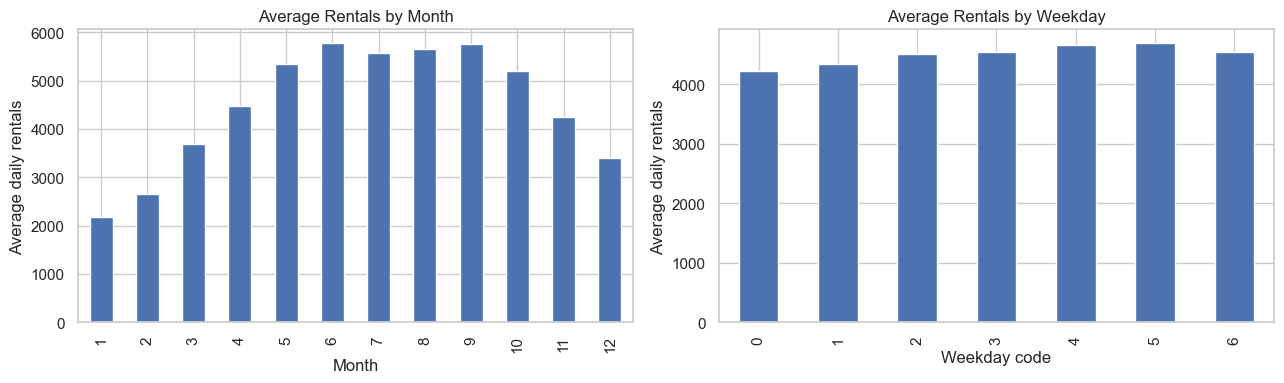

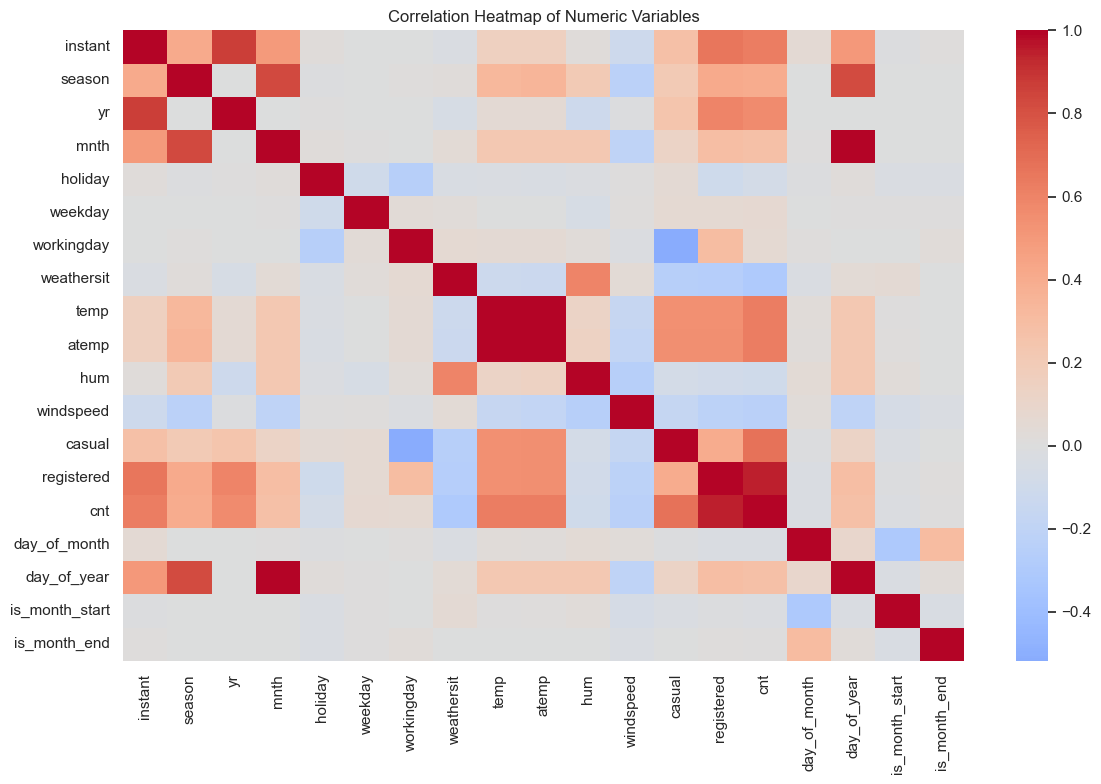

In [6]:
# Average rentals by month and weekday
monthly_avg = data.groupby("mnth", observed=True)["cnt"].mean()
weekday_avg = data.groupby("weekday", observed=True)["cnt"].mean()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
monthly_avg.plot(kind="bar", ax=axes[0])
axes[0].set_title("Average Rentals by Month")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Average daily rentals")

weekday_avg.plot(kind="bar", ax=axes[1])
axes[1].set_title("Average Rentals by Weekday")
axes[1].set_xlabel("Weekday code")
axes[1].set_ylabel("Average daily rentals")
plt.tight_layout()
plt.show()

# Correlation heatmap for numeric columns.
numeric_for_corr = data.select_dtypes(include=np.number)
plt.figure(figsize=(12, 8))
sns.heatmap(numeric_for_corr.corr(), cmap="coolwarm", center=0, annot=False)
plt.title("Correlation Heatmap of Numeric Variables")
plt.tight_layout()
plt.show()


### EDA interpretation

Use the generated charts and summary tables to describe the patterns observed in the dataset. In particular, inspect:

- Whether rentals change over time and between the two years.
- Which seasons and months have higher or lower average rental counts.
- Whether poor weather is associated with lower rentals.
- Whether temperature, humidity and wind speed show relationships with demand.
- Whether the target distribution is skewed or contains unusually high/low observations.

The actual findings should be written after running the notebook and reviewing its output.


## 5. Train-test split and preprocessing

In [7]:
# Chronological split: earlier observations for training, latest observations for testing.
split_index = int(len(X) * 0.80)
X_train, X_test = X.iloc[:split_index].copy(), X.iloc[split_index:].copy()
y_train, y_test = y.iloc[:split_index].copy(), y.iloc[split_index:].copy()

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training date range:", data.loc[X_train.index, "dteday"].min(), "to", data.loc[X_train.index, "dteday"].max())
print("Testing date range:", data.loc[X_test.index, "dteday"].min(), "to", data.loc[X_test.index, "dteday"].max())


Training rows: 584
Testing rows: 147
Training date range: 2011-01-01 00:00:00 to 2012-08-06 00:00:00
Testing date range: 2012-08-07 00:00:00 to 2012-12-31 00:00:00


## 6. Train and compare multiple regression models

The following models are compared:

1. Linear Regression — simple baseline model.
2. Ridge Regression — linear model with regularization.
3. Random Forest Regressor — ensemble of decision trees.
4. Gradient Boosting Regressor — sequential boosting model.
5. HistGradientBoosting Regressor — histogram-based gradient boosting.

The same chronological holdout set is used for all models. Metrics are MAE, RMSE and R². Lower MAE/RMSE and higher R² indicate better performance.


In [8]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(
        n_estimators=400, min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(random_state=RANDOM_STATE),
    "Hist Gradient Boosting": HistGradientBoostingRegressor(
        max_iter=250, learning_rate=0.08, random_state=RANDOM_STATE
    )
}

fitted_models = {}
rows = []

for name, estimator in models.items():
    pipe = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])
    pipe.fit(X_train, y_train)
    predictions = pipe.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    fitted_models[name] = pipe
    rows.append({"Model": name, "MAE": mae, "RMSE": rmse, "R2": r2})

comparison = pd.DataFrame(rows).sort_values("RMSE").reset_index(drop=True)
display(comparison)


,Model,MAE,RMSE,R2
0,Gradient Boosting,754.031248,942.865452,0.747028
1,Hist Gradient Boosting,814.043404,1020.804116,0.703477
2,Ridge Regression,814.417881,1100.668510,0.655264
3,Linear Regression,790.674690,1101.722600,0.654603
4,Random Forest,920.946288,1131.701017,0.635551


## 7. Select the best model and evaluate predictions

In [9]:
best_model_name = comparison.loc[0, "Model"]
best_model = fitted_models[best_model_name]
best_predictions = best_model.predict(X_test)

print("Best model based on lowest test RMSE:", best_model_name)
print("MAE :", round(mean_absolute_error(y_test, best_predictions), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, best_predictions)), 2))
print("R2  :", round(r2_score(y_test, best_predictions), 4))

evaluation = pd.DataFrame({
    "Actual rentals": y_test.values,
    "Predicted rentals": best_predictions
}, index=y_test.index)
evaluation["Error"] = evaluation["Actual rentals"] - evaluation["Predicted rentals"]
display(evaluation.head(15))


Best model based on lowest test RMSE: Gradient Boosting
MAE : 754.03
RMSE: 942.87
R2  : 0.747


,Actual rentals,Predicted rentals,Error
584,7273.0,7019.152869,253.847131
585,7534.0,6964.952483,569.047517
586,7286.0,6900.754796,385.245204
587,5786.0,6435.699709,-649.699709
588,6299.0,6497.025737,-198.025737
589,6544.0,7263.129530,-719.129530
590,6883.0,7240.828520,-357.828520
591,6784.0,6790.750099,-6.750099
592,7347.0,7229.729640,117.270360
593,7605.0,7415.312720,189.687280


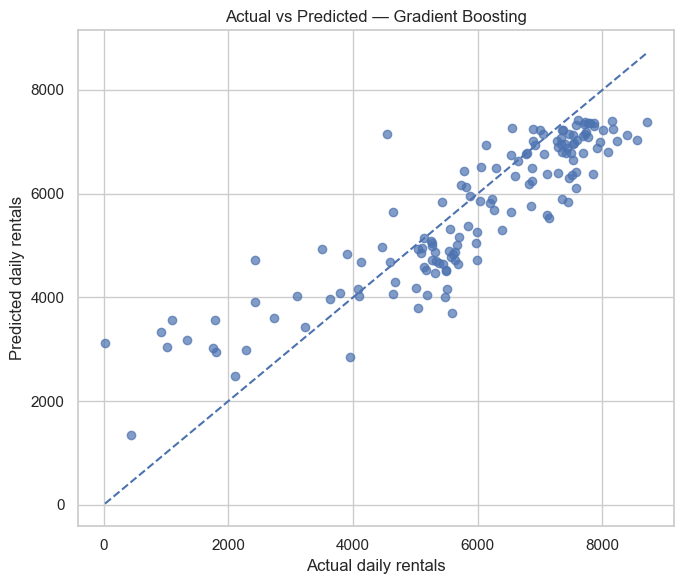

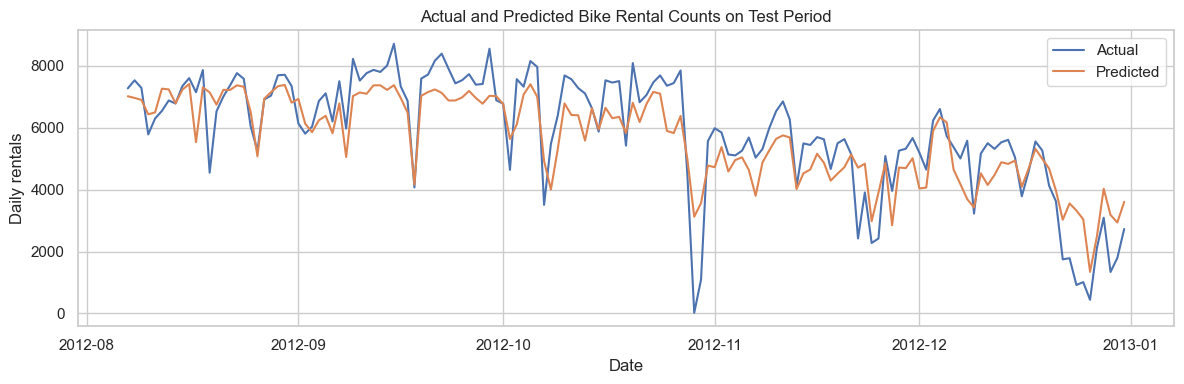

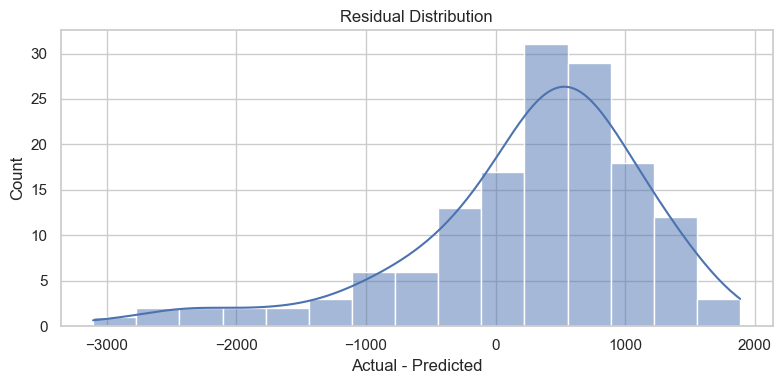

In [10]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, best_predictions, alpha=0.7)
low = min(y_test.min(), best_predictions.min())
high = max(y_test.max(), best_predictions.max())
plt.plot([low, high], [low, high], linestyle="--")
plt.xlabel("Actual daily rentals")
plt.ylabel("Predicted daily rentals")
plt.title(f"Actual vs Predicted — {best_model_name}")
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 4))
plt.plot(data.loc[y_test.index, "dteday"], y_test.values, label="Actual")
plt.plot(data.loc[y_test.index, "dteday"], best_predictions, label="Predicted")
plt.xlabel("Date")
plt.ylabel("Daily rentals")
plt.title("Actual and Predicted Bike Rental Counts on Test Period")
plt.legend()
plt.tight_layout()
plt.show()

residuals = y_test.values - best_predictions
plt.figure(figsize=(8, 4))
sns.histplot(residuals, kde=True)
plt.title("Residual Distribution")
plt.xlabel("Actual - Predicted")
plt.tight_layout()
plt.show()


## 8. Model comparison report

The comparison table above ranks the models by test RMSE. The first row is the best model under this evaluation criterion. Review all three metrics before selecting a model:

- **MAE:** average absolute prediction error, in number of bikes.
- **RMSE:** penalizes large prediction errors more strongly.
- **R²:** proportion of target variation explained by the model.

**Production recommendation:** use the model that performs best on the chronological holdout set, provided its error is operationally acceptable and the validation period represents the intended production scenario. Before deployment, retrain and validate on more recent data, monitor prediction errors and retrain when demand patterns change. The selected model name and measured metrics are printed above when the notebook is executed.


## 9. Challenges faced and techniques used

| Challenge | Technique used | Reason |
|---|---|---|
| Missing or invalid values | Inspect missing values; use median imputation for numeric columns and most-frequent imputation for categorical columns inside the pipeline | Allows the model workflow to handle missing predictor values without manually inserting arbitrary values |
| Duplicate records | Check and remove exact duplicate rows | Avoids counting identical records more than once |
| Date stored as text | Convert `dteday` to datetime and derive calendar features | Makes date-related patterns available to the model |
| Categorical variables stored as numeric codes | Convert coded fields to categorical strings and apply one-hot encoding | Prevents the model from assuming that category codes have meaningful numeric distances |
| Different predictor scales | Apply standard scaling to numeric predictors | Helps scale-sensitive models such as linear and Ridge regression |
| Target leakage risk | Exclude `casual` and `registered`, which add up to `cnt` | Prevents the model from using components of the target to predict the target |
| Time-dependent observations | Use a chronological 80/20 train-test split | Tests on later dates and reduces the risk of training on future records |
| Different model behaviour | Compare several regression algorithms using MAE, RMSE and R² | Provides a consistent basis for model selection |

### Additional limitations

- The dataset covers a historical period and may not represent current travel behaviour.
- The daily dataset contains aggregated counts, so it cannot explain hour-by-hour demand.
- External factors such as local events, road closures and transport disruptions are not included in the listed attributes.
- A single holdout period may not capture all seasonal conditions; time-based cross-validation and later-period testing are recommended before production use.


## 10. Final conclusion

In [11]:
best_row = comparison.iloc[0]
print("PROJECT CONCLUSION")
print("------------------")
print(f"Best model: {best_row['Model']}")
print(f"Test MAE : {best_row['MAE']:.2f} bikes")
print(f"Test RMSE: {best_row['RMSE']:.2f} bikes")
print(f"Test R2  : {best_row['R2']:.4f}")
print()
print("The models were evaluated on a chronological test set.")
print("The model with the lowest test RMSE is the leading candidate under this evaluation.")
print("Production deployment should follow additional time-based validation and monitoring.")


PROJECT CONCLUSION
------------------
Best model: Gradient Boosting
Test MAE : 754.03 bikes
Test RMSE: 942.87 bikes
Test R2  : 0.7470

The models were evaluated on a chronological test set.
The model with the lowest test RMSE is the leading candidate under this evaluation.
Production deployment should follow additional time-based validation and monitoring.
